In [73]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import os
import sys
import glob
import uproot

def gaus(x, A, mean, std):
    return A * np.exp(-1 * (x - mean)**2 / 2*(std))

def sigmoid(x, A, mean, width):
    return (A / (1 + np.exp(-1 * width * (x - mean))))

proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser90.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser20.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser50.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser60.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser40.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser0.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser70.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserT

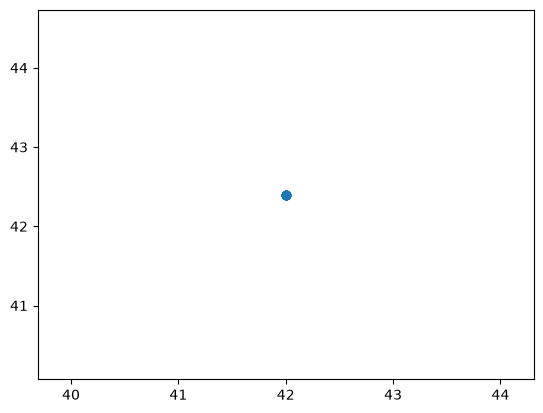

In [74]:
path = "../../Processed_data/"
# path = "../../ZAxisScan/"
# files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.root")
files = glob.glob(f"{path}proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser*pc_Temp16C_Zpos*_Xpos*_Ypos*00000.root")

# files = glob.glob(f"{path}F*--AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.trc")

Z_range = [] # np.linspace(50.0, 50.8, 11)
X_range = [] # np.linspace(41.4, 41.7, 21)
Y_range = []
laser_tune = []

map_plot_x = []
map_plot_y = []
map_plot_z = []

for file in files:
    filename = file.split(path)[1]
    print(filename)
    x_pos = float(filename.split("Xpos")[1].split("_")[0])
    y_pos = float(filename.split("Ypos")[1].split("00000.root")[0])
    z_pos = float(filename.split("Zpos")[1].split("_")[0])
    lt = float(filename.split("mV_Laser")[1].split("pc_")[0])
    map_plot_x.append(x_pos)
    map_plot_y.append(y_pos)
    map_plot_z.append(z_pos)
    laser_tune.append(lt)
    X_range.append(x_pos)
    Y_range.append(y_pos)
    Z_range.append(z_pos)

Z_range = np.unique(Z_range)
X_range = np.unique(X_range)
Y_range = np.unique(Y_range)

# map_plot_x = np.sort(map_plot_x)
# map_plot_z = np.sort(map_plot_z)

plt.scatter(map_plot_x, map_plot_z)
plt.show()

fields = [
    'i_evt',
    # 'channel',
    # 'time',
    # 'baseline',
    'baseline_RMS',
    'noise',
    'amp',
    't_peak',
    'integral',
    # 'intfull',
    # 'risetime',
    # 'decaytime',
    # 'LP2_5',
    # 'LP2_10',
    # 'LP2_15',
    # 'LP2_20',
    # 'LP2_25',
    # 'LP2_30',
    # 'LP2_35',
    # 'LP2_40',
    # 'LP2_45',
    'LP2_50',
    # 'LP2_55',
    # 'LP2_60',
    # 'LP2_65',
    # 'LP2_70',
    # 'LP2_75',
    # 'LP2_80',
    # 'LP2_85',
    # 'LP2_90',
    # 'LP2_95',
    # 'LP2_100',
    # 'LP2_10mV',
    # 'LP2_20mV',
    # 'LP2_30mV',
    # 'LP2_50mV',
    # 'LP2_70mV',
    # 'LP2_90mV',
    # 'LP2_100mV',
    # 'LP2_120mV',
    # 'LP2_140mV',
    # 'LP2_160mV',
    # 'LP2_180mV',
    # 'LP2_200mV',
    # 'linear_RE_5',
    # 'linear_RE_10',
    # 'linear_RE_15',
    # 'linear_RE_20',
    # 'linear_RE_25',
    # 'linear_RE_30',
    # 'linear_RE_35',
    # 'linear_RE_40',
    # 'linear_RE_45',
    # 'linear_RE_50',
    # 'linear_RE_55',
    # 'linear_RE_60',
    # 'linear_RE_65',
    # 'linear_RE_70',
    # 'linear_RE_75',
    # 'linear_RE_80',
    # 'linear_RE_85',
    # 'linear_RE_90',
    # 'linear_RE_95',
    # 'linear_RE_100',
    # 'linear_RE__10mV',
    # 'linear_RE__20mV',
    # 'linear_RE__30mV',
    # 'linear_RE__50mV',
    # 'linear_RE__70mV',
    # 'linear_RE__90mV',
    # 'linear_RE__100mV',
    # 'linear_RE__120mV',
    # 'linear_RE__140mV',
    # 'linear_RE__160mV',
    # 'linear_RE__180mV',
    # 'linear_RE__200mV'
]
    

In [75]:
integral = {}
amp = {}
t_peak = {}
risetime = {}
timestamps = {}
baseline_RMS = {}
risetime = {}
channel = {}
time = {}

for f_i, f in enumerate(files):
    pulse = uproot.open(f)["pulse"].arrays(fields)
    l = f"pos_{map_plot_z[f_i]}_{map_plot_x[f_i]}_{map_plot_y[f_i]}_{laser_tune[f_i]}"
    # channel[l] = pulse["channel"]
    # time[l] = pulse["time"]
    t_peak[l] = pulse["t_peak"]
    integral[l] = pulse["integral"]
    # risetime[l] = pulse["risetime"]
    amp[l] = pulse["amp"]
    baseline_RMS[l] = pulse["baseline_RMS"]
    timestamps[l] = pulse["LP2_50"]
    del pulse

print(amp.keys())

dict_keys(['pos_42.4_42.0_106.0_90.0', 'pos_42.4_42.0_106.0_20.0', 'pos_42.4_42.0_106.0_50.0', 'pos_42.4_42.0_106.0_60.0', 'pos_42.4_42.0_106.0_40.0', 'pos_42.4_42.0_106.0_0.0', 'pos_42.4_42.0_106.0_70.0', 'pos_42.4_42.0_106.0_100.0', 'pos_42.4_42.0_106.0_10.0', 'pos_42.4_42.0_106.0_30.0', 'pos_42.4_42.0_106.0_80.0'])


pos_42.4_42.0_106.0_90.0
31 30
[ 28.63854887  39.22680806 186.92162472]
pos_42.4_42.0_106.0_20.0
31 30
[  13.11232862   39.10418179 -246.40340899]
pos_42.4_42.0_106.0_50.0
31 30
[  12.87515401   39.1336834  -268.93706655]
pos_42.4_42.0_106.0_60.0
31 30
[ 14.4732225   39.12833203 -97.89233901]
pos_42.4_42.0_106.0_40.0
31 30
[  13.67727368   39.10972522 -221.52389512]
pos_42.4_42.0_106.0_0.0
31 30
[  10.86215037   39.06189955 -429.92958984]
pos_42.4_42.0_106.0_70.0


/tmp/ipykernel_1056450/1632829551.py:11: RuntimeWarning: overflow encountered in exp
  return A * np.exp(-1 * (x - mean)**2 / 2*(std))


31 30


RuntimeError: Optimal parameters not found: Number of calls to function has reached maxfev = 800.

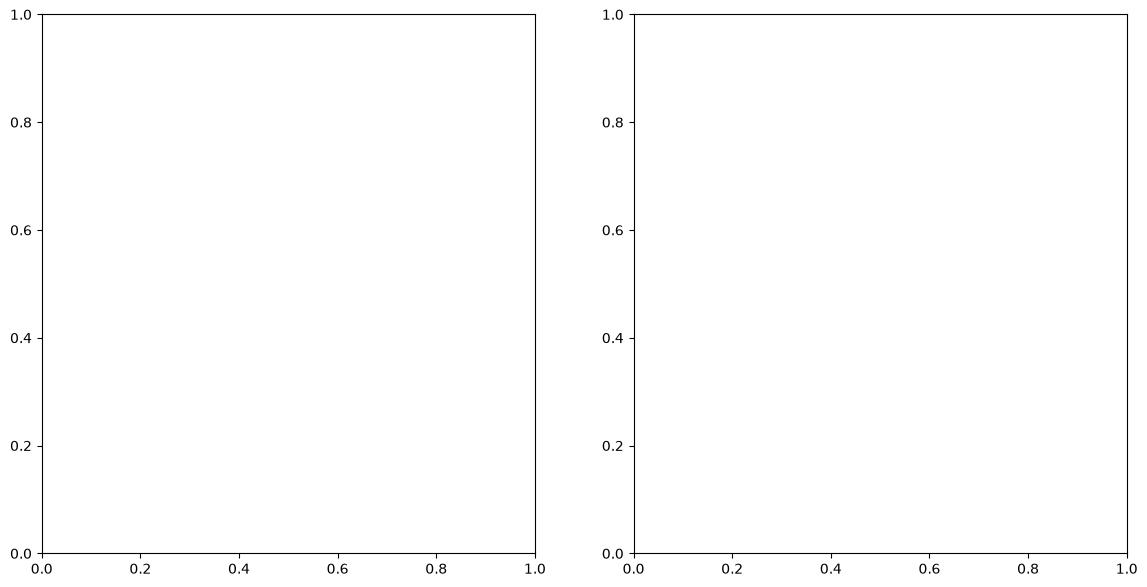

In [77]:
cols = 2
rows = 1
size = 7
channel = 5

fig, ax = plt.subplots(rows, cols, figsize = (size*cols, size*rows))
mean_amps = []
n_events = []
dt_res = []
for lt_i, lt in enumerate(laser_tune):
    for z_i, z in enumerate(Z_range):
        for x_i, x in enumerate(X_range):
            for y_i, y in enumerate(Y_range):
                l = f"pos_{z}_{x}_{y}_{lt}"
                print(l)

                nbins = 30
                mask = (t_peak[l][:,7]<0.96)
                dt = timestamps[l][:,channel] - timestamps[l][:,7]

                # y, x = np.histogram(amp[l][mask][:,channel], bins = nbins)
                # params = curve_fit(gaus, x[0:nbins], y[0:nbins], p0=(np.mean(y[0:nbins]), np.mean(x[0:nbins]), std))

                mean_amps.append(np.mean(amp[l][mask][:,channel]))
                n_events.append(np.mean(dt[mask]))
                std = np.std(dt[mask])
                mean = np.mean(dt[mask])
                y, x = np.histogram(dt[mask], bins = nbins)
                x = np.array(x)
                y = np.array(y)
                print(len(x), len(y))
                
                params = curve_fit(gaus, x[0:nbins], y[0:nbins], p0=(np.mean(y[0:nbins]), np.mean(x[0:nbins]), std)) # , bounds = bounds) # , p0=( np.mean(y), mean, np.std(hist[mask]) ) )
                y_fit = [gaus(i, params[0][0], params[0][1], params[0][2]) for i in x[0:nbins]]
                # plt.show()
                # plt.hist(dt[mask], range = (np.min(dt[mask]), np.max(dt[mask])), bins = nbins,  histtype = "step")
                # plt.plot(x[0:nbins], y_fit, color = "red", marker = "o")
                # plt.show()
                print(params[0])
                dt_res.append(params[0][1])
                # except:
                #     mean_amps.append(0)
                #     n_events.append(0)
print(mean_amps)

sorting = np.argsort(laser_tune)
mean_amps = np.array(mean_amps)
n_events = np.array(n_events)
laser_tune = np.array(laser_tune)
dt_res = np.array(dt_res)

# params = curve_fit(gaus, X_range[mask], mean_amps[mask], p0 = (np.max(mean_amps[mask]), np.mean(X_range[mask]), 10))

print(len(laser_tune), len(mean_amps))

sort = np.argsort(laser_tune)

mask = (laser_tune[sort] != 100)
ax[0].plot(laser_tune[sort][mask], mean_amps[sort][mask], label = f"Z position: {z}", marker = "o")
ax[0].set_xlabel("Laser tune [%]")
ax[0].set_ylabel("Mean amplitude")

ax[1].plot(laser_tune[sort][mask], dt_res[sort][mask], label = f"Z position: {z}", marker = "o")
ax[1].set_xlabel("Laser tune [%]")
ax[1].set_ylabel("Timing resolution[]")

ax[0].grid()
ax[1].grid()
plt.legend()
plt.show()